### State-Quarter Forecasting Analysis

The main forecasting analysis focused on quarterly road traffic crash data across Nigeria's 36 states and the Federal Capital Territory (FCT), covering Q2 2020 to Q4 2025. The original dataset contained 851 state-quarter observations across 23 quarters.

The target variable, total_cases, represented the total number of reported road traffic crash cases for each state and quarter. Alongside historical crash counts, the dataset also included recorded crash causative factors such as speed violation, tyre burst, dangerous driving, route violation and other reported factors.

To ensure that the models relied only on information available before the quarter being predicted, lagged variables were created using observations from previous quarters. This approach helped maintain the forecasting structure of the analysis while reducing the risk of target leakage from using current-quarter crash outcomes or causative factors as predictors.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn


pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

In [3]:
df = pd.read_csv('/Users/amaree/Desktop/Masters Dissertation Dataset/Nigeria Road Crashes Report Cleaned.csv')

In [5]:
# make a quarter map

quarter_map = {
    "Q1": 1,
    "Q2": 2,
    "Q3": 3,
    "Q4": 4
}

df["quarter_num"] = df["quarter"].map(quarter_map)

In [7]:
# create crash-count lags

df = df.sort_values(
    ["state", "year", "quarter_num"]
).reset_index(drop=True)

In [9]:
df["total_cases_lag1"] = (
    df.groupby("state")["total_cases"].shift(1)
)

df["total_cases_lag2"] = (
    df.groupby("state")["total_cases"].shift(2)
)

df["total_cases_lag4"] = (
    df.groupby("state")["total_cases"].shift(4)
)

In [11]:
# verify

df[df["state"] == "Abia"][
    [
        "state",
        "year",
        "quarter",
        "total_cases",
        "total_cases_lag1",
        "total_cases_lag2",
        "total_cases_lag4"
    ]
].head(10)

,state,year,quarter,total_cases,total_cases_lag1,total_cases_lag2,total_cases_lag4
0,Abia,2020,Q2,18,NaN,NaN,NaN
1,Abia,2020,Q3,28,18.0,NaN,NaN
2,Abia,2020,Q4,30,28.0,18.0,NaN
3,Abia,2021,Q1,44,30.0,28.0,NaN
4,Abia,2021,Q2,21,44.0,30.0,18.0
5,Abia,2021,Q3,20,21.0,44.0,28.0
6,Abia,2021,Q4,21,20.0,21.0,30.0
7,Abia,2022,Q1,33,21.0,20.0,44.0
8,Abia,2022,Q2,29,33.0,21.0,21.0
9,Abia,2022,Q3,24,29.0,33.0,20.0


In [13]:
# lag-1 factors with one loop

cause_vars = [
    "spv", "upd", "tbt", "mdv", "bfl", "ovl",
    "dot", "wot", "dgd", "brd", "rtv", "obs",
    "sos", "dad", "pwr", "ftq", "slv", "others"
]


for col in cause_vars:
    df[f"{col}_lag1"] = (
        df.groupby("state")[col].shift(1)
    )

In [15]:
# verify with one state

df[df["state"] == "Abia"][
    [
        "year",
        "quarter",
        "total_cases",
        "spv",
        "spv_lag1",
        "rtv",
        "rtv_lag1",
        "tbt",
        "tbt_lag1"
    ]
].head(8)

,year,quarter,total_cases,spv,spv_lag1,rtv,rtv_lag1,tbt,tbt_lag1
0,2020,Q2,18,10,NaN,2,NaN,4,NaN
1,2020,Q3,28,18,10.0,2,2.0,1,4.0
2,2020,Q4,30,19,18.0,3,2.0,4,1.0
3,2021,Q1,44,7,19.0,3,3.0,10,4.0
4,2021,Q2,21,20,7.0,4,3.0,1,10.0
5,2021,Q3,20,4,20.0,3,4.0,5,1.0
6,2021,Q4,21,8,4.0,2,3.0,2,5.0
7,2022,Q1,33,20,8.0,2,2.0,5,2.0


In [17]:
# define the feature columns

cause_lag_vars = [f"{col}_lag1" for col in cause_vars]

feature_cols = [
    "state",
    "quarter_num",
    "total_cases_lag1",
    "total_cases_lag2",
    "total_cases_lag4"
] + cause_lag_vars

target = "total_cases"

In [19]:
#check

feature_cols

['state',
 'quarter_num',
 'total_cases_lag1',
 'total_cases_lag2',
 'total_cases_lag4',
 'spv_lag1',
 'upd_lag1',
 'tbt_lag1',
 'mdv_lag1',
 'bfl_lag1',
 'ovl_lag1',
 'dot_lag1',
 'wot_lag1',
 'dgd_lag1',
 'brd_lag1',
 'rtv_lag1',
 'obs_lag1',
 'sos_lag1',
 'dad_lag1',
 'pwr_lag1',
 'ftq_lag1',
 'slv_lag1',
 'others_lag1']

In [21]:
# modelling dataframe


df["period"] = pd.PeriodIndex(
    df["year"].astype(str) + "Q" + df["quarter_num"].astype(str),
    freq="Q"
)

model_df = df[
    ["year", "quarter", "period"] + feature_cols + [target]
].copy()

In [23]:
model_df.shape

(851, 27)

In [25]:
model_df.head()

,year,quarter,period,state,quarter_num,total_cases_lag1,total_cases_lag2,total_cases_lag4,spv_lag1,upd_lag1,tbt_lag1,mdv_lag1,bfl_lag1,ovl_lag1,dot_lag1,wot_lag1,dgd_lag1,brd_lag1,rtv_lag1,obs_lag1,sos_lag1,dad_lag1,pwr_lag1,ftq_lag1,slv_lag1,others_lag1,total_cases
0,2020,Q2,2020Q2,Abia,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18
1,2020,Q3,2020Q3,Abia,3,18.0,NaN,NaN,10.0,0.0,4.0,0.0,3.0,0.0,0.0,1.0,0.0,0.0,2.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,28
2,2020,Q4,2020Q4,Abia,4,28.0,18.0,NaN,18.0,0.0,1.0,1.0,4.0,0.0,0.0,5.0,2.0,8.0,2.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,30
3,2021,Q1,2021Q1,Abia,1,30.0,28.0,NaN,19.0,0.0,4.0,0.0,3.0,0.0,0.0,5.0,0.0,0.0,3.0,0.0,0.0,0.0,0.0,0.0,2.0,1.0,44
4,2021,Q2,2021Q2,Abia,2,44.0,30.0,18.0,7.0,0.0,10.0,1.0,4.0,0.0,0.0,3.0,0.0,0.0,3.0,0.0,0.0,0.0,0.0,0.0,7.0,1.0,21


In [27]:
#lag-generated NaNs

model_df.isnull().sum()

year                  0
quarter               0
period                0
state                 0
quarter_num           0
total_cases_lag1     37
total_cases_lag2     74
total_cases_lag4    148
spv_lag1             37
upd_lag1             37
tbt_lag1             37
mdv_lag1             37
bfl_lag1             37
ovl_lag1             37
dot_lag1             37
wot_lag1             37
dgd_lag1             37
brd_lag1             37
rtv_lag1             37
obs_lag1             37
sos_lag1             37
dad_lag1             37
pwr_lag1             37
ftq_lag1             37
slv_lag1             37
others_lag1          37
total_cases           0
dtype: int64

In [29]:
model_df = model_df.dropna().reset_index(drop=True)

In [31]:
model_df.shape

(703, 27)

### Feature Engineering

Lagged variables were created separately for each state to ensure that the historical order of observations was maintained. Three lagged crash-count variables were generated: the previous quarter (total_cases_lag1), two quarters earlier (total_cases_lag2) and the same quarter in the previous year (total_cases_lag4).

One-quarter lagged variables were also created for the 18 harmonised crash causative factors. State and quarter were retained as categorical variables and subsequently encoded for use in the forecasting models.

Creating the four-quarter lag reduced the dataset from 851 to 703 observations, covering 37 geographical units across 19 quarters from Q2 2021 to Q4 2025.

The reduction in observations was due to the initial quarters required to generate the historical lagged variables, rather than missing crash records in the original dataset.

In [35]:
model_df.isnull().sum().sum()

0

In [37]:
# time distribution

model_df.groupby("year").size()

year
2021    111
2022    148
2023    148
2024    148
2025    148
dtype: int64

In [39]:
model_df.groupby(["year", "quarter"]).size()

year  quarter
2021  Q2         37
      Q3         37
      Q4         37
2022  Q1         37
      Q2         37
      Q3         37
      Q4         37
2023  Q1         37
      Q2         37
      Q3         37
      Q4         37
2024  Q1         37
      Q2         37
      Q3         37
      Q4         37
2025  Q1         37
      Q2         37
      Q3         37
      Q4         37
dtype: int64

### Train & Test

In [42]:
train_df = model_df[
    (model_df["period"] >= pd.Period("2021Q2", freq="Q")) &
    (model_df["period"] <= pd.Period("2024Q2", freq="Q"))
].copy()

val_df = model_df[
    (model_df["period"] >= pd.Period("2024Q3", freq="Q")) &
    (model_df["period"] <= pd.Period("2024Q4", freq="Q"))
].copy()

test_df = model_df[
    (model_df["period"] >= pd.Period("2025Q1", freq="Q")) &
    (model_df["period"] <= pd.Period("2025Q4", freq="Q"))
].copy()

In [44]:
print("Training:", train_df.shape)
print("Validation:", val_df.shape)
print("Test:", test_df.shape)

Training: (481, 27)
Validation: (74, 27)
Test: (148, 27)


In [46]:
# verify the periods

print(
    "Training:",
    train_df["period"].min(),
    "to",
    train_df["period"].max()
)

print(
    "Validation:",
    val_df["period"].min(),
    "to",
    val_df["period"].max()
)

print(
    "Test:",
    test_df["period"].min(),
    "to",
    test_df["period"].max()
)

Training: 2021Q2 to 2024Q2
Validation: 2024Q3 to 2024Q4
Test: 2025Q1 to 2025Q4


In [49]:
print("Training states:", train_df["state"].nunique())
print("Validation states:", val_df["state"].nunique())
print("Test states:", test_df["state"].nunique())

Training states: 37
Validation states: 37
Test states: 37


In [51]:
# define x and y

X_train = train_df[feature_cols].copy()
y_train = train_df["total_cases"].copy()

X_val = val_df[feature_cols].copy()
y_val = val_df["total_cases"].copy()

X_test = test_df[feature_cols].copy()
y_test = test_df["total_cases"].copy()

In [53]:
print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (481, 23)
y_train: (481,)
X_val: (74, 23)
y_val: (74,)
X_test: (148, 23)
y_test: (148,)


### Temporal Validation Strategy

A chronological train-test split was used instead of a random split to ensure that future observations were not used to predict earlier periods.

For model selection, observations from Q2 2021 to Q2 2024 were used for training, while Q3 and Q4 2024 were reserved for validation. After selecting the best-performing model, it was retrained using all available observations up to Q4 2024 and evaluated on the unseen 2025 test dataset.

An expanding-window cross-validation approach was also used during model development. With each successive fold, the training period was extended to include more historical observations, while model performance was evaluated on later quarters.

This approach better reflected the forecasting process, where predictions of future road traffic crash cases are made using only information available from previous periods.

In [57]:
# naive baseline

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

baseline_val_pred = X_val["total_cases_lag1"]

In [59]:
baseline_val_mae = mean_absolute_error(
    y_val,
    baseline_val_pred
)

baseline_val_rmse = np.sqrt(
    mean_squared_error(
        y_val,
        baseline_val_pred
    )
)

baseline_val_r2 = r2_score(
    y_val,
    baseline_val_pred
)

print("Naive Baseline - Validation")
print("---------------------------")
print(f"MAE:  {baseline_val_mae:.2f}")
print(f"RMSE: {baseline_val_rmse:.2f}")
print(f"R²:   {baseline_val_r2:.3f}")

Naive Baseline - Validation
---------------------------
MAE:  17.80
RMSE: 27.52
R²:   0.721


In [61]:
seasonal_val_pred = X_val["total_cases_lag4"]

seasonal_mae = mean_absolute_error(
    y_val, seasonal_val_pred
)

seasonal_rmse = np.sqrt(
    mean_squared_error(y_val, seasonal_val_pred)
)

seasonal_r2 = r2_score(
    y_val, seasonal_val_pred
)

print("Seasonal Naive Baseline - Validation")
print("------------------------------------")
print(f"MAE:  {seasonal_mae:.2f}")
print(f"RMSE: {seasonal_rmse:.2f}")
print(f"R²:   {seasonal_r2:.3f}")

Seasonal Naive Baseline - Validation
------------------------------------
MAE:  17.30
RMSE: 32.78
R²:   0.604


In [63]:
state_means = (
    train_df.groupby("state")["total_cases"]
    .mean()
)

state_mean_val_pred = (
    val_df["state"]
    .map(state_means)
)

state_mean_mae = mean_absolute_error(
    y_val, state_mean_val_pred
)

state_mean_rmse = np.sqrt(
    mean_squared_error(y_val, state_mean_val_pred)
)

state_mean_r2 = r2_score(
    y_val, state_mean_val_pred
)

print("State Mean Baseline - Validation")
print("--------------------------------")
print(f"MAE:  {state_mean_mae:.2f}")
print(f"RMSE: {state_mean_rmse:.2f}")
print(f"R²:   {state_mean_r2:.3f}")

State Mean Baseline - Validation
--------------------------------
MAE:  24.12
RMSE: 40.47
R²:   0.396


### Linear Regression

In [66]:
# pre-processing

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

In [68]:
categorical_features = [
    "state",
    "quarter_num"
]

numeric_features = [
    col for col in feature_cols
    if col not in categorical_features
]

print("Categorical features:", categorical_features)
print("Number of numerical features:", len(numeric_features))
print("Numerical features:", numeric_features)

Categorical features: ['state', 'quarter_num']
Number of numerical features: 21
Numerical features: ['total_cases_lag1', 'total_cases_lag2', 'total_cases_lag4', 'spv_lag1', 'upd_lag1', 'tbt_lag1', 'mdv_lag1', 'bfl_lag1', 'ovl_lag1', 'dot_lag1', 'wot_lag1', 'dgd_lag1', 'brd_lag1', 'rtv_lag1', 'obs_lag1', 'sos_lag1', 'dad_lag1', 'pwr_lag1', 'ftq_lag1', 'slv_lag1', 'others_lag1']


In [70]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                drop="first"
            ),
            categorical_features
        ),
        (
            "numeric",
            StandardScaler(),
            numeric_features
        )
    ]
)

In [72]:
# build LR

lr_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", LinearRegression())
    ]
)

In [74]:
lr_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](23,)","['state','quarter_num','total_cases_lag1',...,'ftq_lag1','slv_lag1', 'others_lag1']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,23
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categorical', ...), ('numeric', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through

In [76]:
lr_val_pred = lr_model.predict(X_val)

In [78]:
# Evaluate LR

lr_val_mae = mean_absolute_error(
    y_val,
    lr_val_pred
)

lr_val_rmse = np.sqrt(
    mean_squared_error(
        y_val,
        lr_val_pred
    )
)

lr_val_r2 = r2_score(
    y_val,
    lr_val_pred
)

print("Linear Regression - Validation")
print("------------------------------")
print(f"MAE:  {lr_val_mae:.2f}")
print(f"RMSE: {lr_val_rmse:.2f}")
print(f"R²:   {lr_val_r2:.3f}")

Linear Regression - Validation
------------------------------
MAE:  20.40
RMSE: 33.08
R²:   0.597


In [80]:
comparison = pd.DataFrame({
    "Model": [
        "Lag-1 Naive",
        "Seasonal Naive",
        "State Mean",
        "Linear Regression"
    ],
    "MAE": [
        17.80,
        17.30,
        24.12,
        lr_val_mae
    ],
    "RMSE": [
        27.52,
        32.78,
        40.47,
        lr_val_rmse
    ],
    "R2": [
        0.721,
        0.604,
        0.396,
        lr_val_r2
    ]
})

comparison.round(3)

,Model,MAE,RMSE,R2
0,Lag-1 Naive,17.800,27.520,0.721
1,Seasonal Naive,17.300,32.780,0.604
2,State Mean,24.120,40.470,0.396
3,Linear Regression,20.402,33.077,0.597


### Random Forest

In [83]:
from sklearn.ensemble import RandomForestRegressor

rf_preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore"
            ),
            categorical_features
        ),
        (
            "numeric",
            "passthrough",
            numeric_features
        )
    ]
)

In [85]:
rf_model = Pipeline(
    steps=[
        ("preprocessor", rf_preprocessor),
        (
            "model",
            RandomForestRegressor(
                n_estimators=500,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

In [87]:
# fit training

rf_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](23,)","['state','quarter_num','total_cases_lag1',...,'ftq_lag1','slv_lag1', 'others_lag1']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,23
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categorical', ...), ('numeric', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through

In [89]:
rf_val_pred = rf_model.predict(X_val)

In [91]:
rf_val_mae = mean_absolute_error(
    y_val,
    rf_val_pred
)

rf_val_rmse = np.sqrt(
    mean_squared_error(
        y_val,
        rf_val_pred
    )
)

rf_val_r2 = r2_score(
    y_val,
    rf_val_pred
)

print("Random Forest - Validation")
print("--------------------------")
print(f"MAE:  {rf_val_mae:.2f}")
print(f"RMSE: {rf_val_rmse:.2f}")
print(f"R²:   {rf_val_r2:.3f}")

Random Forest - Validation
--------------------------
MAE:  16.12
RMSE: 24.95
R²:   0.771


### Gradient Boosting

In [94]:
from sklearn.ensemble import GradientBoostingRegressor

gb_model = Pipeline(
    steps=[
        ("preprocessor", rf_preprocessor),
        (
            "model",
            GradientBoostingRegressor(
                random_state=42
            )
        )
    ]
)

gb_model.fit(X_train, y_train)

gb_val_pred = gb_model.predict(X_val)

In [96]:
gb_val_mae = mean_absolute_error(
    y_val,
    gb_val_pred
)

gb_val_rmse = np.sqrt(
    mean_squared_error(
        y_val,
        gb_val_pred
    )
)

gb_val_r2 = r2_score(
    y_val,
    gb_val_pred
)

print("Gradient Boosting - Validation")
print("------------------------------")
print(f"MAE:  {gb_val_mae:.2f}")
print(f"RMSE: {gb_val_rmse:.2f}")
print(f"R²:   {gb_val_r2:.3f}")

Gradient Boosting - Validation
------------------------------
MAE:  17.96
RMSE: 27.18
R²:   0.728


In [98]:
comparison = pd.DataFrame({
    "Model": [
        "Lag-1 Naive",
        "Seasonal Naive",
        "State Mean",
        "Linear Regression",
        "Random Forest",
        "Gradient Boosting"
    ],
    "MAE": [
        17.80,
        17.30,
        24.12,
        lr_val_mae,
        rf_val_mae,
        gb_val_mae
    ],
    "RMSE": [
        27.52,
        32.78,
        40.47,
        lr_val_rmse,
        rf_val_rmse,
        gb_val_rmse
    ],
    "R2": [
        0.721,
        0.604,
        0.396,
        lr_val_r2,
        rf_val_r2,
        gb_val_r2
    ]
})

comparison.round(3)

,Model,MAE,RMSE,R2
0,Lag-1 Naive,17.800,27.520,0.721
1,Seasonal Naive,17.300,32.780,0.604
2,State Mean,24.120,40.470,0.396
3,Linear Regression,20.402,33.077,0.597
4,Random Forest,16.125,24.948,0.771
5,Gradient Boosting,17.962,27.176,0.728


In [100]:
## Temporal folds

import numpy as np

cv_splits = []

fold_definitions = [
    ("2021Q2", "2022Q4", "2023Q1", "2023Q2"),
    ("2021Q2", "2023Q2", "2023Q3", "2023Q4"),
    ("2021Q2", "2023Q4", "2024Q1", "2024Q2")
]

for train_start, train_end, val_start, val_end in fold_definitions:
    
    train_mask = (
        (train_df["period"] >= pd.Period(train_start, freq="Q")) &
        (train_df["period"] <= pd.Period(train_end, freq="Q"))
    )
    
    val_mask = (
        (train_df["period"] >= pd.Period(val_start, freq="Q")) &
        (train_df["period"] <= pd.Period(val_end, freq="Q"))
    )
    
    train_indices = np.where(train_mask)[0]
    val_indices = np.where(val_mask)[0]
    
    cv_splits.append((train_indices, val_indices))

In [102]:
for i, (train_idx, val_idx) in enumerate(cv_splits, start=1):
    
    fold_train = train_df.iloc[train_idx]
    fold_val = train_df.iloc[val_idx]
    
    print(f"Fold {i}")
    print(
        "Train:",
        fold_train["period"].min(),
        "to",
        fold_train["period"].max(),
        "| Rows:",
        len(fold_train)
    )
    
    print(
        "Validation:",
        fold_val["period"].min(),
        "to",
        fold_val["period"].max(),
        "| Rows:",
        len(fold_val)
    )
    
    print("-" * 50)

Fold 1
Train: 2021Q2 to 2022Q4 | Rows: 259
Validation: 2023Q1 to 2023Q2 | Rows: 74
--------------------------------------------------
Fold 2
Train: 2021Q2 to 2023Q2 | Rows: 333
Validation: 2023Q3 to 2023Q4 | Rows: 74
--------------------------------------------------
Fold 3
Train: 2021Q2 to 2023Q4 | Rows: 407
Validation: 2024Q1 to 2024Q2 | Rows: 74
--------------------------------------------------


In [104]:
# tune random forest

from sklearn.model_selection import RandomizedSearchCV

rf_param_grid = {
    "model__n_estimators": [200, 300, 500, 700, 1000],
    
    "model__max_depth": [
        None, 5, 10, 15, 20
    ],
    
    "model__min_samples_split": [
        2, 5, 10, 15
    ],
    
    "model__min_samples_leaf": [
        1, 2, 4, 6, 10
    ],
    
    "model__max_features": [
        1.0,
        "sqrt",
        0.5,
        0.75
    ]
}

In [106]:
rf_search = RandomizedSearchCV(
    estimator=rf_model,
    param_distributions=rf_param_grid,
    n_iter=50,
    scoring="neg_root_mean_squared_error",
    cv=cv_splits,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

In [108]:
rf_search.fit(X_train, y_train)

Fitting 3 folds for each of 50 candidates, totalling 150 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'model__max_depth': [None, 5, ...], 'model__max_features': [1.0, 'sqrt', ...], 'model__min_samples_leaf': [1, 2, ...], 'model__min_samples_split': [2, 5, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",50
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.","[(array([ 0, ...72, 473, 474]), ...), (array([ 0, ...74, 475, 476]), ...), ...]"
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at th

In [110]:
print("Best Random Forest Parameters:")
print(rf_search.best_params_)

print()

print(
    "Best CV RMSE:",
    -rf_search.best_score_
)

Best Random Forest Parameters:
{'model__n_estimators': 700, 'model__min_samples_split': 5, 'model__min_samples_leaf': 2, 'model__max_features': 'sqrt', 'model__max_depth': None}

Best CV RMSE: 22.776990090974238


In [112]:
# evaluate tuned RF

tuned_rf = rf_search.best_estimator_

In [114]:
tuned_rf_val_pred = tuned_rf.predict(X_val)

In [116]:
tuned_rf_val_mae = mean_absolute_error(
    y_val,
    tuned_rf_val_pred
)

tuned_rf_val_rmse = np.sqrt(
    mean_squared_error(
        y_val,
        tuned_rf_val_pred
    )
)

tuned_rf_val_r2 = r2_score(
    y_val,
    tuned_rf_val_pred
)

print("Tuned Random Forest - Validation")
print("--------------------------------")
print(f"MAE:  {tuned_rf_val_mae:.2f}")
print(f"RMSE: {tuned_rf_val_rmse:.2f}")
print(f"R²:   {tuned_rf_val_r2:.3f}")

Tuned Random Forest - Validation
--------------------------------
MAE:  17.58
RMSE: 24.35
R²:   0.781


In [118]:
rf_comparison = pd.DataFrame({
    "Model": [
        "Lag-1 Naive",
        "Untuned Random Forest",
        "Tuned Random Forest"
    ],
    "MAE": [
        17.80,
        rf_val_mae,
        tuned_rf_val_mae
    ],
    "RMSE": [
        27.52,
        rf_val_rmse,
        tuned_rf_val_rmse
    ],
    "R2": [
        0.721,
        rf_val_r2,
        tuned_rf_val_r2
    ]
})

rf_comparison.round(3)

,Model,MAE,RMSE,R2
0,Lag-1 Naive,17.800,27.520,0.721
1,Untuned Random Forest,16.125,24.948,0.771
2,Tuned Random Forest,17.583,24.349,0.781


In [120]:
# Tune Gradient Boosting

gb_param_grid = {
    "model__n_estimators": [
        50, 100, 200, 300, 500
    ],
    "model__learning_rate": [
        0.01, 0.03, 0.05, 0.1, 0.2
    ],
    "model__max_depth": [
        1, 2, 3, 4, 5
    ],
    "model__min_samples_split": [
        2, 5, 10, 15
    ],
    "model__min_samples_leaf": [
        1, 2, 4, 6, 10
    ],
    "model__subsample": [
        0.6, 0.8, 1.0
    ],
    "model__max_features": [
        None, "sqrt", 0.5, 0.75
    ]
}

In [122]:
gb_search = RandomizedSearchCV(
    estimator=gb_model,
    param_distributions=gb_param_grid,
    n_iter=50,
    scoring="neg_root_mean_squared_error",
    cv=cv_splits,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

gb_search.fit(X_train, y_train)

Fitting 3 folds for each of 50 candidates, totalling 150 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'model__learning_rate': [0.01, 0.03, ...], 'model__max_depth': [1, 2, ...], 'model__max_features': [None, 'sqrt', ...], 'model__min_samples_leaf': [1, 2, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",50
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.","[(array([ 0, ...72, 473, 474]), ...), (array([ 0, ...74, 475, 476]), ...), ...]"
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at th

In [124]:
print("Best Gradient Boosting Parameters:")
print(gb_search.best_params_)

print()

print(
    "Best CV RMSE:",
    -gb_search.best_score_
)

Best Gradient Boosting Parameters:
{'model__subsample': 0.8, 'model__n_estimators': 100, 'model__min_samples_split': 2, 'model__min_samples_leaf': 6, 'model__max_features': 'sqrt', 'model__max_depth': 5, 'model__learning_rate': 0.03}

Best CV RMSE: 23.27295124169079


In [126]:
# evaluate tuned GB

tuned_gb = gb_search.best_estimator_

tuned_gb_val_pred = tuned_gb.predict(X_val)

tuned_gb_val_mae = mean_absolute_error(
    y_val,
    tuned_gb_val_pred
)

tuned_gb_val_rmse = np.sqrt(
    mean_squared_error(
        y_val,
        tuned_gb_val_pred
    )
)

tuned_gb_val_r2 = r2_score(
    y_val,
    tuned_gb_val_pred
)

print("Tuned Gradient Boosting - Validation")
print("------------------------------------")
print(f"MAE:  {tuned_gb_val_mae:.2f}")
print(f"RMSE: {tuned_gb_val_rmse:.2f}")
print(f"R²:   {tuned_gb_val_r2:.3f}")

Tuned Gradient Boosting - Validation
------------------------------------
MAE:  18.05
RMSE: 24.86
R²:   0.772


In [128]:
final_val_comparison = pd.DataFrame({
    "Model": [
        "Lag-1 Naive",
        "Seasonal Naive",
        "State Mean",
        "Linear Regression",
        "Untuned Random Forest",
        "Tuned Random Forest",
        "Untuned Gradient Boosting",
        "Tuned Gradient Boosting"
    ],
    
    "MAE": [
        17.80,
        17.30,
        24.12,
        lr_val_mae,
        rf_val_mae,
        tuned_rf_val_mae,
        gb_val_mae,
        tuned_gb_val_mae
    ],
    
    "RMSE": [
        27.52,
        32.78,
        40.47,
        lr_val_rmse,
        rf_val_rmse,
        tuned_rf_val_rmse,
        gb_val_rmse,
        tuned_gb_val_rmse
    ],
    
    "R2": [
        0.721,
        0.604,
        0.396,
        lr_val_r2,
        rf_val_r2,
        tuned_rf_val_r2,
        gb_val_r2,
        tuned_gb_val_r2
    ]
})

final_val_comparison.round(3)

,Model,MAE,RMSE,R2
0,Lag-1 Naive,17.800,27.520,0.721
1,Seasonal Naive,17.300,32.780,0.604
2,State Mean,24.120,40.470,0.396
3,Linear Regression,20.402,33.077,0.597
4,Untuned Random Forest,16.125,24.948,0.771
5,Tuned Random Forest,17.583,24.349,0.781
6,Untuned Gradient Boosting,17.962,27.176,0.728
7,Tuned Gradient Boosting,18.048,24.862,0.772


### Model Selection and Validation Performance

Three machine-learning models were evaluated: Linear Regression, Random Forest and Gradient Boosting. Their performance was also compared against three simple forecasting benchmarks based on the previous quarter's crash count, the same quarter in the previous year and the historical average for each state.

Random Forest recorded the strongest overall performance during validation. The untuned Random Forest achieved the lowest MAE of 16.125, while the tuned Random Forest recorded the lowest RMSE of 24.349 and the highest R² of 0.781. The tuned Gradient Boosting model also performed well, achieving an RMSE of 24.862 and an R² of 0.772.

Linear Regression performed less strongly, with an MAE of 20.402, RMSE of 33.077 and R² of 0.597. Its performance was also weaker than the previous-quarter benchmark, highlighting the importance of comparing machine-learning models against simpler forecasting methods.

Although hyperparameter tuning did not improve Random Forest's MAE, it reduced RMSE and improved R², indicating better overall performance on these measures.

The tuned Random Forest was therefore selected for the final evaluation, as it achieved the strongest RMSE and R² results while maintaining a competitive MAE.

In [132]:
rf_val_results = val_df[
    ["state", "year", "quarter", "total_cases"]
].copy()

rf_val_results["predicted"] = tuned_rf_val_pred

rf_val_results["residual"] = (
    rf_val_results["total_cases"]
    - rf_val_results["predicted"]
)

rf_val_results["absolute_error"] = (
    rf_val_results["residual"].abs()
)

rf_val_results.head(10)

,state,year,quarter,total_cases,predicted,residual,absolute_error
13,Abia,2024,Q3,15,27.017772,-12.017772,12.017772
14,Abia,2024,Q4,20,22.367824,-2.367824,2.367824
32,Adamawa,2024,Q3,43,34.102576,8.897424,8.897424
33,Adamawa,2024,Q4,53,47.737607,5.262393,5.262393
51,Akwa Ibom,2024,Q3,7,18.276962,-11.276962,11.276962
52,Akwa Ibom,2024,Q4,17,14.908812,2.091188,2.091188
70,Anambra,2024,Q3,21,32.625390,-11.625390,11.625390
71,Anambra,2024,Q4,25,26.370855,-1.370855,1.370855
89,Bauchi,2024,Q3,46,69.027352,-23.027352,23.027352
90,Bauchi,2024,Q4,83,52.343146,30.656854,30.656854


In [134]:
rf_val_results["residual"].describe()

count    74.000000
mean     -2.793358
std      24.353035
min     -95.657997
25%     -15.372296
50%      -7.339079
75%       7.372607
max      57.062889
Name: residual, dtype: float64

In [136]:
rf_val_results.sort_values(
    "absolute_error",
    ascending=False
).head(10)

,state,year,quarter,total_cases,predicted,residual,absolute_error
279,FCT,2024,Q3,159,254.657997,-95.657997,95.657997
488,Nasarawa,2024,Q3,101,163.740584,-62.740584,62.740584
527,Ogun,2024,Q4,243,185.937111,57.062889,57.062889
470,Lagos,2024,Q4,156,99.387496,56.612504,56.612504
356,Kaduna,2024,Q4,191,141.718938,49.281062,49.281062
336,Jigawa,2024,Q3,117,70.573508,46.426492,46.426492
280,FCT,2024,Q4,181,227.116927,-46.116927,46.116927
584,Oyo,2024,Q4,161,118.250061,42.749939,42.749939
603,Plateau,2024,Q4,94,53.955245,40.044755,40.044755
508,Niger,2024,Q4,127,89.109312,37.890688,37.890688


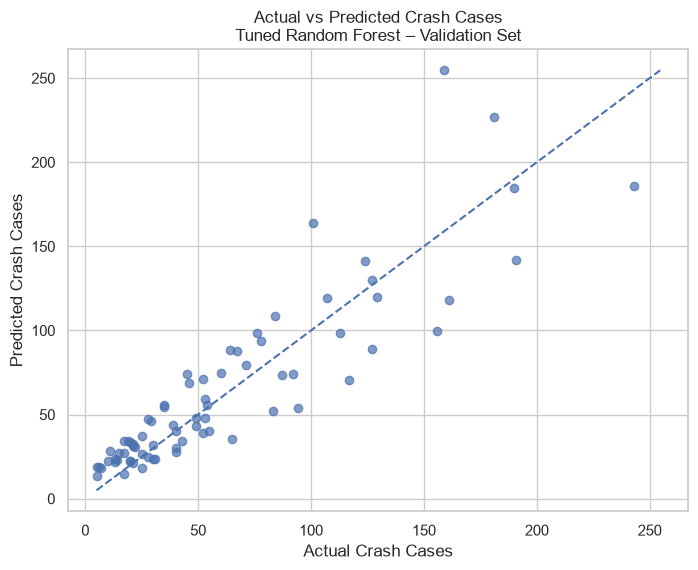

In [138]:
# actual vs predicted

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(
    rf_val_results["total_cases"],
    rf_val_results["predicted"],
    alpha=0.7
)

min_val = min(
    rf_val_results["total_cases"].min(),
    rf_val_results["predicted"].min()
)

max_val = max(
    rf_val_results["total_cases"].max(),
    rf_val_results["predicted"].max()
)

plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    linestyle="--"
)

plt.xlabel("Actual Crash Cases")
plt.ylabel("Predicted Crash Cases")
plt.title(
    "Actual vs Predicted Crash Cases\n"
    "Tuned Random Forest – Validation Set"
)

plt.show()

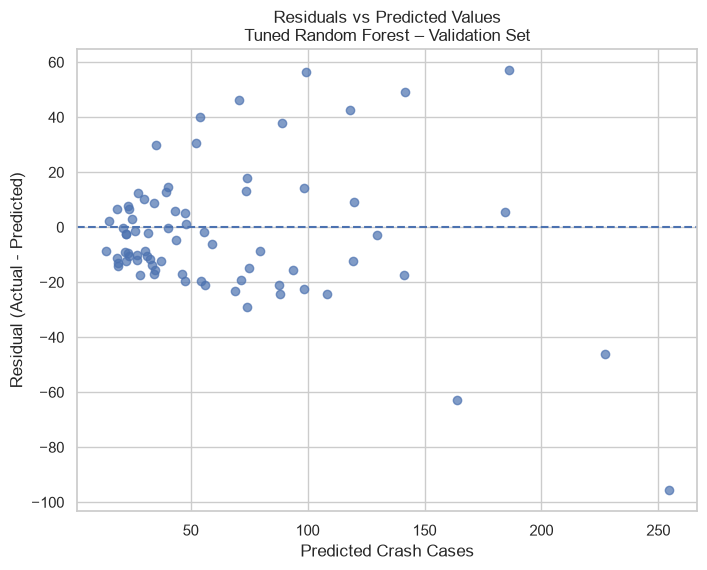

In [140]:
# residuals vs predictions

plt.figure(figsize=(8, 6))

plt.scatter(
    rf_val_results["predicted"],
    rf_val_results["residual"],
    alpha=0.7
)

plt.axhline(
    y=0,
    linestyle="--"
)

plt.xlabel("Predicted Crash Cases")
plt.ylabel("Residual (Actual - Predicted)")
plt.title(
    "Residuals vs Predicted Values\n"
    "Tuned Random Forest – Validation Set"
)

plt.show()

In [142]:
# combine training and validation

final_train_df = pd.concat(
    [train_df, val_df],
    ignore_index=True
)

print(final_train_df.shape)

print(
    "Final training period:",
    final_train_df["period"].min(),
    "to",
    final_train_df["period"].max()
)

(555, 27)
Final training period: 2021Q2 to 2024Q4


In [144]:
X_final_train = final_train_df[feature_cols].copy()
y_final_train = final_train_df["total_cases"].copy()

print(X_final_train.shape)
print(y_final_train.shape)

(555, 23)
(555,)


In [146]:
# refit the selected rf

from sklearn.base import clone

final_rf = clone(tuned_rf)

final_rf.fit(
    X_final_train,
    y_final_train
)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](23,)","['state','quarter_num','total_cases_lag1',...,'ftq_lag1','slv_lag1', 'others_lag1']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,23
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categorical', ...), ('numeric', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through

In [148]:
# final rf test

final_rf_test_pred = final_rf.predict(X_test)

final_rf_test_mae = mean_absolute_error(
    y_test,
    final_rf_test_pred
)

final_rf_test_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        final_rf_test_pred
    )
)

final_rf_test_r2 = r2_score(
    y_test,
    final_rf_test_pred
)

print("Final Random Forest - 2025 Test")
print("--------------------------------")
print(f"MAE:  {final_rf_test_mae:.2f}")
print(f"RMSE: {final_rf_test_rmse:.2f}")
print(f"R²:   {final_rf_test_r2:.3f}")

Final Random Forest - 2025 Test
--------------------------------
MAE:  13.08
RMSE: 18.01
R²:   0.903


In [150]:
# Additional 2025 Random Forest error analysis


rf_2025_results = test_df[
    ["state", "year", "quarter", "total_cases"]
].copy()

rf_2025_results["predicted"] = final_rf_test_pred

rf_2025_results["residual"] = (
    rf_2025_results["total_cases"]
    - rf_2025_results["predicted"]
)

rf_2025_results["absolute_error"] = (
    rf_2025_results["residual"].abs()
)

rf_2025_results["squared_error"] = (
    rf_2025_results["residual"] ** 2
)

print(rf_2025_results.head())


      state  year quarter  total_cases  predicted  residual  absolute_error  \
15     Abia  2025      Q1           19  23.575559 -4.575559        4.575559   
16     Abia  2025      Q2           13  22.894264 -9.894264        9.894264   
17     Abia  2025      Q3           20  17.996256  2.003744        2.003744   
18     Abia  2025      Q4           28  24.390101  3.609899        3.609899   
34  Adamawa  2025      Q1           49  40.510982  8.489018        8.489018   

    squared_error  
15      20.935740  
16      97.896454  
17       4.014990  
18      13.031369  
34      72.063424  


In [152]:
# MAE per State

state_errors = (
    rf_2025_results.groupby("state")
    .agg(
        n=("absolute_error", "size"),
        MAE=("absolute_error", "mean"),
        MSE=("squared_error", "mean")
    )
    .reset_index()
)

# Calculate RMSE for each state
state_errors["RMSE"] = np.sqrt(state_errors["MSE"])

# Remove MSE column
state_errors = state_errors.drop(columns=["MSE"])

# Rank states from lowest to highest MAE
state_errors = state_errors.sort_values(
    by="MAE",
    ascending=True
).reset_index(drop=True)

print(state_errors)

          state  n        MAE       RMSE
0         Kwara  4   4.419981   5.383494
1       Bayelsa  4   4.978690   5.109097
2          Abia  4   5.020866   5.828348
3   Cross River  4   5.675282   7.073299
4          Yobe  4   6.072192   6.543490
5       Anambra  4   6.432647   7.265506
6        Sokoto  4   6.619805   6.833998
7        Taraba  4   6.889793   8.112126
8       Katsina  4   7.037052   8.259953
9         Delta  4   7.286188   8.271339
10      Zamfara  4   7.359977   8.950138
11          Edo  4   7.401805   9.164849
12        Kebbi  4   7.515336   8.329716
13        Ekiti  4   7.620359   8.437725
14    Akwa Ibom  4   7.960842   8.767018
15       Rivers  4   8.295175   9.813264
16      Adamawa  4   8.517218   9.578124
17          Oyo  4   8.821551  10.175356
18          Imo  4   8.949542  10.871174
19        Borno  4   9.397837  10.273548
20       Ebonyi  4   9.530435  10.389372
21        Lagos  4  11.772213  13.413120
22         Ondo  4  13.257567  14.188816
23        Gombe 

In [154]:

# Five states with the lowest MAE
best_5_states = state_errors.head(5)

print("Five states with the lowest MAE:")
display(best_5_states)

# Five states with the highest MAE
worst_5_states = state_errors.tail(5).sort_values(
    by="MAE",
    ascending=False
)

print("Five states with the highest MAE:")
display(worst_5_states)

Five states with the lowest MAE:


,state,n,MAE,RMSE
0,Kwara,4,4.419981,5.383494
1,Bayelsa,4,4.978690,5.109097
2,Abia,4,5.020866,5.828348
3,Cross River,4,5.675282,7.073299
4,Yobe,4,6.072192,6.543490


Five states with the highest MAE:


,state,n,MAE,RMSE
36,FCT,4,37.231145,42.624132
35,Nasarawa,4,28.573108,37.573728
34,Ogun,4,26.561892,35.008618
33,Kaduna,4,26.366224,33.918434
32,Kano,4,21.952661,25.243884


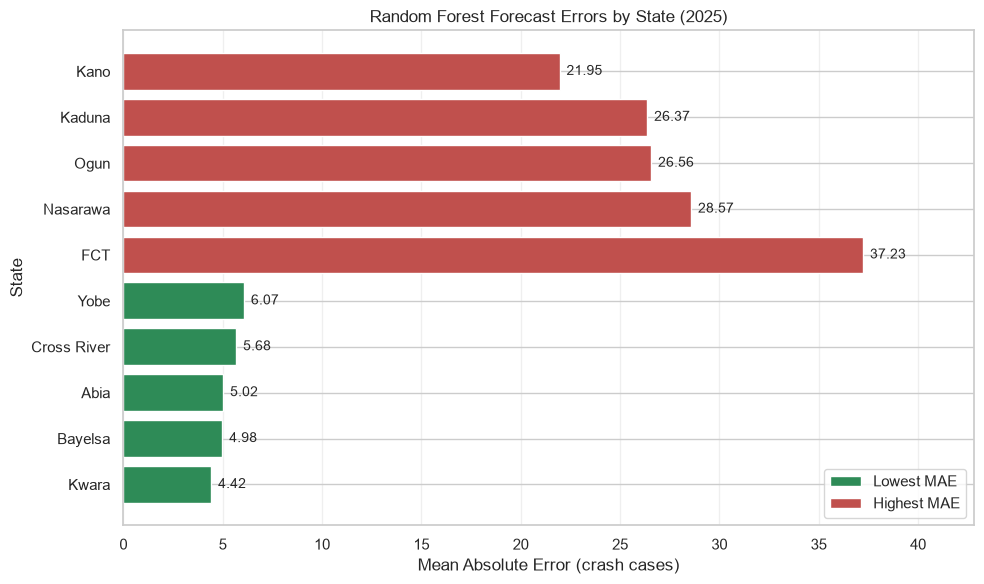

In [175]:
# Visualise state-level errors with two colours

from matplotlib.patches import Patch

# Combine the five lowest and five highest MAE states
selected_states = pd.concat([
    best_5_states,
    worst_5_states
])

# Assign colours based on performance group
colors = (
    ["#2E8B57"] * len(best_5_states) +
    ["#C0504D"] * len(worst_5_states)
)

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.barh(
    selected_states["state"],
    selected_states["MAE"],
    color=colors
)

# Display MAE values at the end of each bar
ax.bar_label(
    bars,
    fmt="%.2f",
    padding=5,
    fontsize=10
)

# Add space so the labels are not cut off
ax.set_xlim(0, selected_states["MAE"].max() * 1.15)

ax.set_xlabel("Mean Absolute Error (crash cases)")
ax.set_ylabel("State")
ax.set_title("Random Forest Forecast Errors by State (2025)")

# Add legend
legend_elements = [
    Patch(facecolor="#2E8B57", label="Lowest MAE"),
    Patch(facecolor="#C0504D", label="Highest MAE")
]

ax.legend(
    handles=legend_elements,
    loc="lower right"
)

ax.grid(axis="x", alpha=0.3)
ax.set_axisbelow(True)

plt.tight_layout()

# Save high-resolution figure
plt.savefig(
    "RF_2025_State_MAE_Comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [160]:
# Calculate quarterly Random Forest errors

quarter_errors = (
    rf_2025_results.groupby("quarter")
    .agg(
        n=("absolute_error", "size"),
        MAE=("absolute_error", "mean"),
        MSE=("squared_error", "mean")
    )
    .reset_index()
)

# Calculate RMSE
quarter_errors["RMSE"] = np.sqrt(
    quarter_errors["MSE"]
)

# Remove MSE
quarter_errors = quarter_errors.drop(
    columns=["MSE"]
)

# Arrange quarters chronologically
quarter_errors["quarter"] = pd.Categorical(
    quarter_errors["quarter"],
    categories=["Q1", "Q2", "Q3", "Q4"],
    ordered=True
)

quarter_errors = quarter_errors.sort_values("quarter")

display(quarter_errors)

,quarter,n,MAE,RMSE
0,Q1,37,14.104786,20.086069
1,Q2,37,13.183691,19.971700
2,Q3,37,12.562255,16.094930
3,Q4,37,12.474782,15.342508


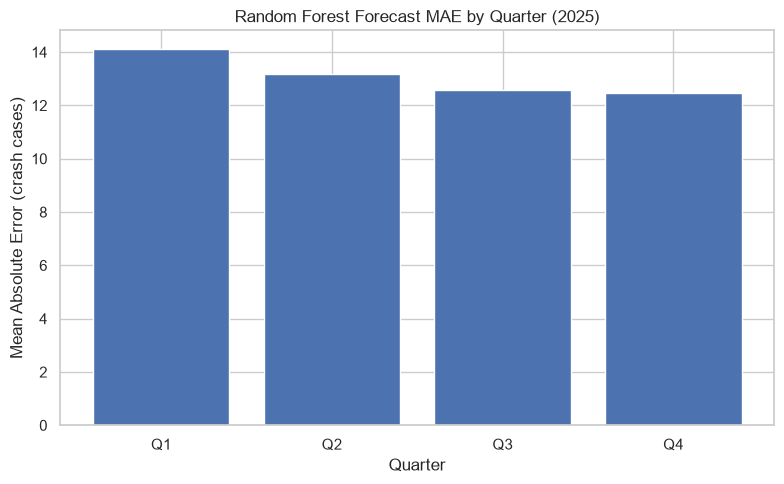

In [162]:
# Visualise quarterly MAE

plt.figure(figsize=(8, 5))

plt.bar(
    quarter_errors["quarter"].astype(str),
    quarter_errors["MAE"]
)

plt.xlabel("Quarter")
plt.ylabel("Mean Absolute Error (crash cases)")
plt.title("Random Forest Forecast MAE by Quarter (2025)")

plt.tight_layout()
plt.show()

### Quarterly Random Forest Error Analysis (2025)

The Random Forest model's forecasting errors were examined across all four quarters of 2025, with 37 state-level observations in each quarter.

The MAE decreased from 14.105 in Q1 to 12.475 in Q4, representing a reduction of approximately 11.6%. Similarly, RMSE declined from 20.086 to 15.343, suggesting that prediction errors generally became smaller, with fewer large errors influencing the results in the later quarters.

These results suggest that the model performed better towards the end of the 2025 test period. However, the findings are limited to one year of test data and should be interpreted within the rolling one-quarter-ahead forecasting approach, where actual observations from previous quarters were used to predict the next quarter.

In [165]:
# Distribution of 2025 Random Forest absolute errors

absolute_errors = rf_2025_results["absolute_error"]

error_distribution = pd.DataFrame({
    "Metric": [
        "Mean Absolute Error (MAE)",
        "Median Absolute Error",
        "25th Percentile (Q1)",
        "75th Percentile (Q3)",
        "Interquartile Range (IQR)",
        "Maximum Absolute Error"
    ],
    "Value": [
        absolute_errors.mean(),
        absolute_errors.median(),
        absolute_errors.quantile(0.25),
        absolute_errors.quantile(0.75),
        absolute_errors.quantile(0.75)
        - absolute_errors.quantile(0.25),
        absolute_errors.max()
    ]
})

display(error_distribution.round(3))

,Metric,Value
0,Mean Absolute Error (MAE),13.081
1,Median Absolute Error,9.395
2,25th Percentile (Q1),4.916
3,75th Percentile (Q3),16.934
4,Interquartile Range (IQR),12.018
5,Maximum Absolute Error,69.892


### Random Forest Absolute Error Distribution (2025)

The distribution of absolute prediction errors was examined across 148 state-quarter observations in 2025. The Random Forest model recorded an MAE of 13.081 cases and a median absolute error of 9.395 cases.

The interquartile range was 12.018 cases, with the middle 50% of prediction errors falling between 4.916 and 16.934 cases. This shows that most errors were relatively small, although some observations recorded larger differences between actual and predicted crash counts.

The highest absolute error was 69.892 cases, indicating that the model produced considerably larger prediction errors for some state-quarter observations compared with the typical forecast.

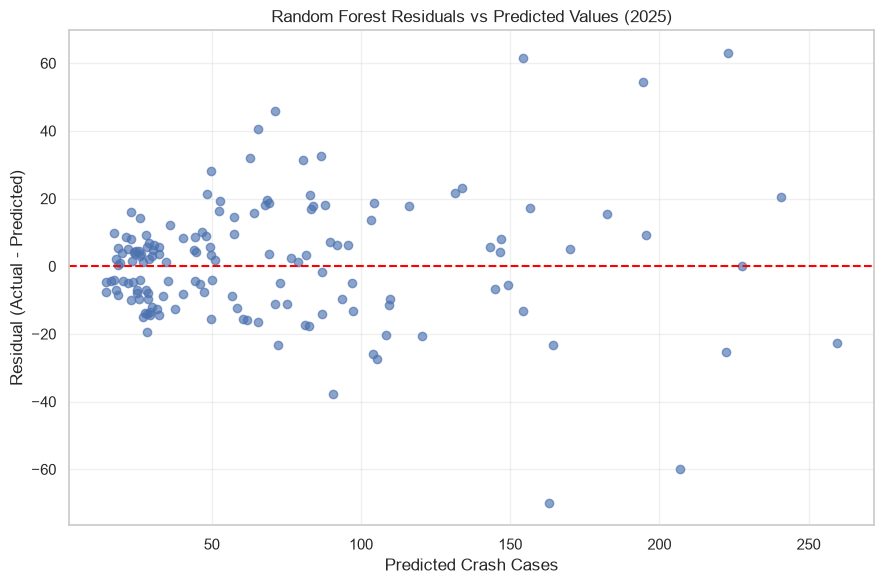

In [168]:
# Residuals versus predicted crash counts

plt.figure(figsize=(9, 6))

plt.scatter(
    rf_2025_results["predicted"],
    rf_2025_results["residual"],
    alpha=0.65,
    color="#4C72B0"
)

# Reference line for zero prediction error
plt.axhline(
    y=0,
    color="red",
    linestyle="--",
    linewidth=1.5
)

plt.xlabel("Predicted Crash Cases")
plt.ylabel("Residual (Actual - Predicted)")
plt.title("Random Forest Residuals vs Predicted Values (2025)")

plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    "RF_2025_Residuals_vs_Predicted.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


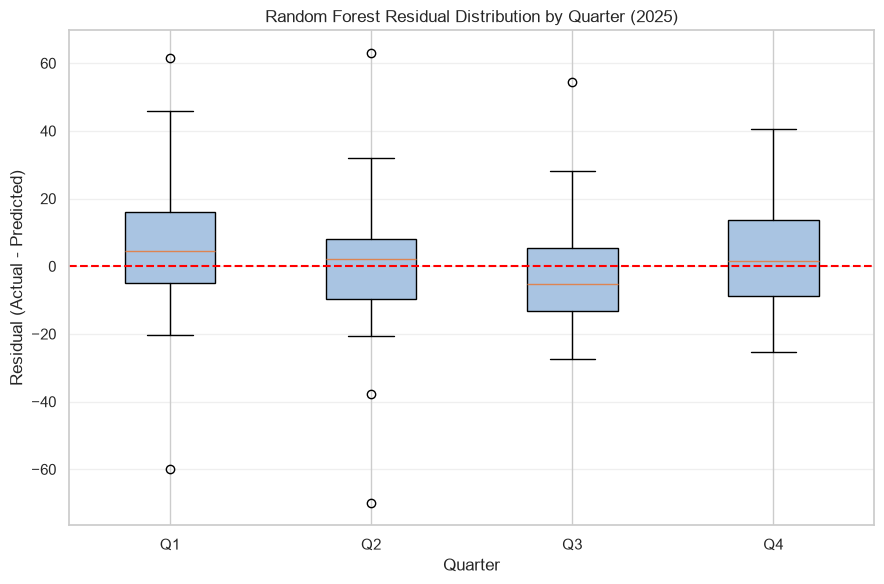

In [170]:
# Residual distribution by quarter

quarter_order = ["Q1", "Q2", "Q3", "Q4"]

quarter_residuals = [
    rf_2025_results.loc[
        rf_2025_results["quarter"] == q,
        "residual"
    ].values
    for q in quarter_order
]

plt.figure(figsize=(9, 6))

plt.boxplot(
    quarter_residuals,
    tick_labels=quarter_order,
    patch_artist=True,
    boxprops=dict(facecolor="#A9C4E2")
)

plt.axhline(
    y=0,
    color="red",
    linestyle="--",
    linewidth=1.5
)

plt.xlabel("Quarter")
plt.ylabel("Residual (Actual - Predicted)")
plt.title("Random Forest Residual Distribution by Quarter (2025)")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "RF_2025_Residuals_by_Quarter.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Random Forest Residual Diagnostics (2025)

Residual analysis was conducted using the 148 predictions generated by the final Random Forest model on the 2025 test dataset.

The residuals-versus-predicted-values plot shows that prediction errors occurred on both sides of zero, with a wider spread at higher predicted crash counts. This suggests that the variation in prediction errors may increase as crash counts become higher, indicating potential heteroscedasticity.

The quarterly boxplots also show differences in residual distributions across 2025. Q1 and Q2 recorded several extreme prediction errors, while Q3 had a slightly negative median residual. In Q4, the median residual was close to zero, with fewer observations showing unusually large errors.

These findings support the state-level and quarterly MAE analyses by showing that, although the Random Forest model achieved strong overall forecasting performance, its prediction accuracy varied across states, quarters and individual observations.